R2-score линейной модели на тестовой выборке: 0.88


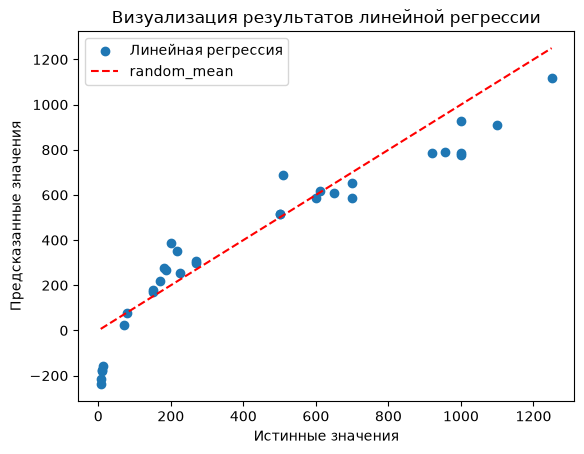

R2-score полиномиальной модели на тестовой выборке: 0.97


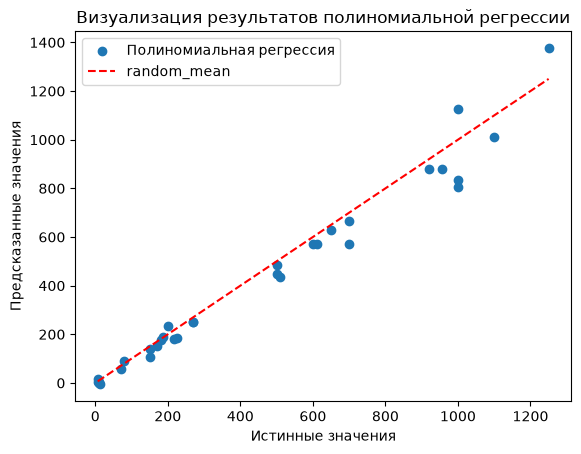

Модели успешно обучены и оценены!


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score

# 1. Загрузка и очистка данных
df = pd.read_csv('Fish.csv')
df_clean = df.dropna(subset=['Weight'])

# Выбираем все признаки по условию задания
X = df_clean[['Length1', 'Length2', 'Length3', 'Height', 'Width']]
y = df_clean['Weight']

# Разделяем на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Обучаем модель линейной регрессии
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Предсказания на тестовой выборке
linear_y_pred = linear_model.predict(X_test)

# Оценка линейной модели
linear_r2 = r2_score(y_test, linear_y_pred)
print(f"R2-score линейной модели на тестовой выборке: {linear_r2:.2f}")

# Визуализация результатов линейной регрессии
plt.scatter(y_test, linear_y_pred, label='Линейная регрессия')

# Добавляем идеальную линию
min_val, max_val = min(y_test), max(y_test)
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='random_mean')

plt.xlabel('Истинные значения')
plt.ylabel('Предсказанные значения')
plt.title('Визуализация результатов линейной регрессии')
plt.legend()
plt.show()

# Обучаем модель полиномиальной регрессии
poly_features = PolynomialFeatures(degree=2)
X_train_poly = poly_features.fit_transform(X_train)
X_test_poly = poly_features.transform(X_test)

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

# Предсказания на тестовой выборке
poly_y_pred = poly_model.predict(X_test_poly)

# Оценка полиномиальной модели
poly_r2 = r2_score(y_test, poly_y_pred)
print(f"R2-score полиномиальной модели на тестовой выборке: {poly_r2:.2f}")

# Визуализация результатов полиномиальной регрессии
plt.scatter(y_test, poly_y_pred, label='Полиномиальная регрессия')

# Добавляем идеальную линию
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='random_mean')

plt.xlabel('Истинные значения')
plt.ylabel('Предсказанные значения')
plt.title('Визуализация результатов полиномиальной регрессии')
plt.legend()
plt.show()

print("Модели успешно обучены и оценены!")

# Выводы 

## Линейная регрессия

- **R2-score на тестовой выборке:** 0.88
- **Описание:** Линейная модель показала R2-score на тестовой выборке равный 0.88. Это значение означает, что модель объясняет 88% изменчивости в данных. Однако, такое низкое значение R2-score может указывать на то, что линейные модели не являются наилучшим выбором для данных, возможно, из-за нелинейных зависимостей.

## Полиномиальная регрессия

- **R2-score на тестовой выборке:** 0.97
- **Описание:** Полиномиальная модель с степенью 2 показала R2-score на тестовой выборке равный 0.97. Это значение намного лучше, чем у линейной модели, что указывает на то, что полиномиальная модель лучше всего справляется с описанием данных, возможно, из-за более сложной формы зависимостей.

## Вывод

В целом, полиномиальная модель с степенью 2 показала лучшие результаты по сравнению с линейной моделью. Это подтверждает, что данные могут быть лучше описаны с использованием более сложных моделей, таких как полиномиальная регрессия. Однако, стоит отметить, что выбранная степень полинома должна быть оптимальной и не должна быть слишком высокой, чтобы избежать переобучения.

Рекомендуется провести дополнительный анализ для подтверждения качества модели и возможного нахождения оптимальной степени полинома. Также можно рассмотреть другие методы регрессии или использование признаков, которые могут улучшить результаты модели.